In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [29]:
df = pd.read_csv("/content/ML activity.zip")

In [32]:
display(df.head())
display(df.tail())
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:", df.columns.tolist())

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,NaN,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0
505,0.04741,0.0,11.93,0.0,0.573,6.030,NaN,2.5050,1,273,21.0,396.90,7.88,11.9


Rows: 506
Columns: 14

Column names: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']


In [34]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,486.000000,486.000000,486.000000,486.000000,506.000000,506.000000,486.000000,506.000000,506.000000,506.000000,506.000000,506.000000,486.000000,506.000000
mean,3.611874,11.211934,11.083992,0.069959,0.554695,6.284634,68.518519,3.795043,9.549407,408.237154,18.455534,356.674032,12.715432,22.532806
std,8.720192,23.388876,6.835896,0.255340,0.115878,0.702617,27.999513,2.105710,8.707259,168.537116,2.164946,91.294864,7.155871,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.081900,0.000000,5.190000,0.000000,0.449000,5.885500,45.175000,2.100175,4.000000,279.000000,17.400000,375.377500,7.125000,17.025000
50%,0.253715,0.000000,9.690000,0.000000,0.538000,6.208500,76.800000,3.207450,5.000000,330.000000,19.050000,391.440000,11.430000,21.200000
75%,3.560263,12.500000,18.100000,0.000000,0.624000,6.623500,93.975000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [35]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())

Missing values in each column:
CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
MEDV        0
dtype: int64

Total missing values: 120
Exact duplicate rows: 0


In [36]:
df_clean = df.copy().dropna()
print("Shape after checking missing values:", df_clean.shape)

Shape after checking missing values: (394, 14)


In [38]:
# Select input feature (e.g., Average Number of Rooms) and target (House Price)
X = df_clean[["RM"]]
y = df_clean["MEDV"]

print("Input feature:", X.columns.tolist())
print("Target:", y.name)

Input feature: ['RM']
Target: MEDV


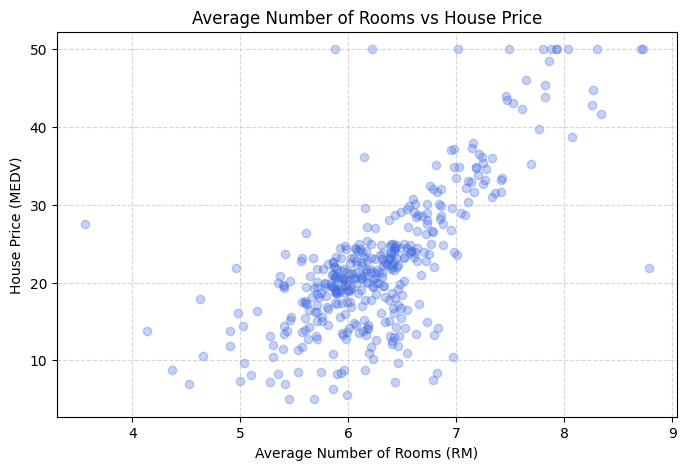

In [40]:
plt.figure(figsize=(8, 5))
plt.scatter(X["RM"], y, alpha=0.3, color='royalblue')
plt.title("Average Number of Rooms vs House Price")
plt.xlabel("Average Number of Rooms (RM)")
plt.ylabel("House Price (MEDV)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 315
Testing records: 79


In [43]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained successfully.")

coefficient = model.coef_[0]
intercept = model.intercept_
print("Coefficient (slope):", coefficient)
print("Intercept:", intercept)
print(f"\nEquation: Predicted MedHouseVal = {intercept:.4f} + {coefficient:.4f} * MedInc")

Model trained successfully.
Coefficient (slope): 9.400024188533527
Intercept: -36.954128828920524

Equation: Predicted MedHouseVal = -36.9541 + 9.4000 * MedInc


In [44]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({"Actual House Value": y_test.values, "Predicted House Value": y_pred})
display(comparison.head(10))

,Actual House Value,Predicted House Value
0,25.0,21.429421
1,18.6,18.355613
2,21.0,20.508219
3,23.5,22.172023
4,17.5,15.394606
5,33.8,30.754245
6,19.7,19.098215
7,24.8,27.633437
8,32.0,26.796835
9,14.0,21.081621


In [45]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")

MAE: 4.2050
MSE: 43.9715
RMSE: 6.6311
R-squared (R2): 0.4787


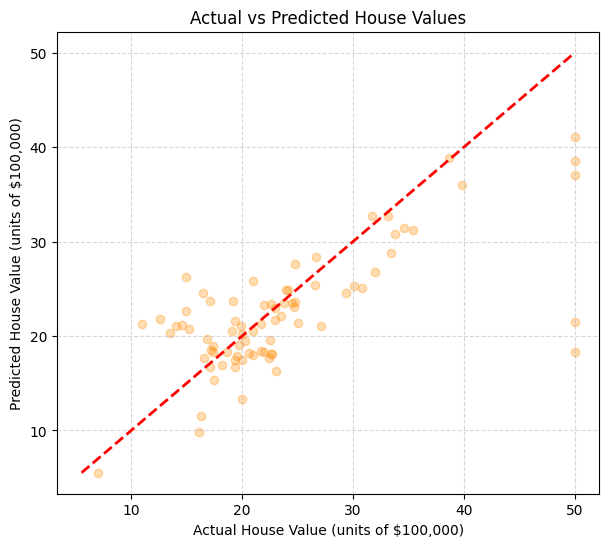

In [46]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='darkorange')
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--", color='red', linewidth=2)
plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual House Value (units of $100,000)")
plt.ylabel("Predicted House Value (units of $100,000)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [49]:
# Use the median value of the 'RM' column instead of 'MedInc'
new_rooms = X_train["RM"].median()
new_data = pd.DataFrame({"RM": [new_rooms]})
new_prediction = model.predict(new_data)[0]

print("New average rooms:", new_rooms)
print(f"Predicted house price (MEDV): {new_prediction:.4f}")
print(f"Approximate value in dollars: ${new_prediction * 1000:,.2f}") # Note: Boston MEDV is typically in thousands of dollars

New average rooms: 6.208
Predicted house price (MEDV): 21.4012
Approximate value in dollars: $21,401.22
